## 1. Найти данные для кластеризации. Данные в группе не должны повторяться. Если признаки в данных имеют очень сильно разные масштабы, то необходимо данные предварительно нормализовать.

**Источник данных:** GitHub-репозиторий `damir77d/Machine_Learning_clustering-of-Russian-regions`.  
**Файл:** `BUND2.csv`.  
**Ссылка:** https://github.com/damir77d/Machine_Learning_clustering-of-Russian-regions

**Описание набора данных:** Датасет содержит социально-экономические показатели 85 субъектов Российской Федерации. Каждая строка соответствует одному региону, столбцы — числовые признаки (плотность населения, общая численность, уровень образования, зарплаты, уровень бедности, преступность и т.д.). Данные не имеют меток кластеров, что соответствует задаче обучения без учителя.

**Необходимость нормализации:** Признаки имеют разный порядок величин (от долей единицы до миллионов), поэтому перед кластеризацией необходимо выполнить нормализацию – привести каждый признак к нулевому среднему и единичному стандартному отклонению. Это требование задания и необходимое условие для корректной работы алгоритмов, основанных на расчете расстояний.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('BUND2.csv', sep=',')

regions_rus = df['Regions, rus'].copy()

X = df.select_dtypes(include=[np.number])

if 'Total population per 1k' in X.columns:
    X = X.drop(columns=['Total population per 1k'])
    print("Признак 'Total population per 1k' удален как дублирующий.")

print(f"Количество объектов: {X.shape[0]}")
print(f"Количество признаков: {X.shape[1]}")

print("\nСтатистики ДО нормализации:")
display(X.describe().T[['mean', 'std', 'min', 'max']])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("\nСтатистики ПОСЛЕ нормализации:")
display(X_scaled_df.describe().T[['mean', 'std', 'min', 'max']])

print("\nГотово! Данные нормализованы. Переменная X_scaled готова к кластеризации.")

Признак 'Total population per 1k' удален как дублирующий.
Количество объектов: 85
Количество признаков: 13

Статистики ДО нормализации:


,mean,std,min,max
Population вensity per km2,1.376555e+02,6.736690e+02,0.0700,4.950430e+03
Total population,1.731772e+06,1.820691e+06,44111.0000,1.267808e+07
Share of people with higher education. 2010. %,2.021176e+01,4.015132e+00,10.0000,4.000000e+01
Median salary. 2019. rubles,3.379347e+04,1.342253e+04,19796.0000,7.754200e+04
Unemployment rate. 2017. %,6.435294e+00,3.592178e+00,1.4000,2.700000e+01
Share of poor people. 2017. %,1.534471e+01,5.593055e+00,7.5000,4.150000e+01
Gross regional product per capita. 2016. rubles,4.336448e+04,6.419999e+04,9281.8400,5.026345e+05
Terrorist_crimes_2017,1.540000e-01,3.713784e-01,0.0000,1.810000e+00
Murders and attempted murders. 2017,8.058824e-01,4.958621e-01,0.1600,2.970000e+00
Criminal possesion of weapons. 2017,2.344706e+00,1.511394e+00,0.3900,8.630000e+00



Статистики ПОСЛЕ нормализации:


,mean,std,min,max
Population вensity per km2,1.991871e-17,1.005935,-0.205445,7.186522
Total population,-4.310278e-17,1.005935,-0.932435,6.047852
Share of people with higher education. 2010. %,1.880848e-16,1.005935,-2.558414,4.957663
Median salary. 2019. rubles,1.881665e-17,1.005935,-1.049023,3.278679
Unemployment rate. 2017. %,-3.317608e-16,1.005935,-1.410058,5.758834
Share of poor people. 2017. %,-5.146210e-16,1.005935,-1.410904,4.704141
Gross regional product per capita. 2016. rubles,5.877651e-18,1.005935,-0.534033,7.196196
Terrorist_crimes_2017,8.816477e-17,1.005935,-0.417132,4.485528
Murders and attempted murders. 2017,4.049049e-16,1.005935,-1.310274,4.390255
Criminal possesion of weapons. 2017,-1.567374e-17,1.005935,-1.300989,4.183288



Готово! Данные нормализованы. Переменная X_scaled готова к кластеризации.


## 2. Провести кластеризацию данных с помощью алгоритма k-means. Использовать "правило локтя" и коэффициент силуэта для поиска  оптимального количества кластеров.

Для определения оптимального количества кластеров \(k\) используются два метода:
1. **"Правило локтя"** – строится график зависимости внутрикластерной суммы квадратов от числа кластеров. Оптимальное \(k\) находится в точке «перелома» (изгиба) графика, после которой уменьшение ошибки становится незначительным.
2. **Коэффициент силуэта** – метрика от -1 до 1, показывающая, насколько объект похож на свой кластер по сравнению с соседними. Чем ближе значение к 1, тем лучше разделение. Оптимальное \(k\) соответствует пиковому значению метрики.

Построим графики для \(k\) от 2 до 10.

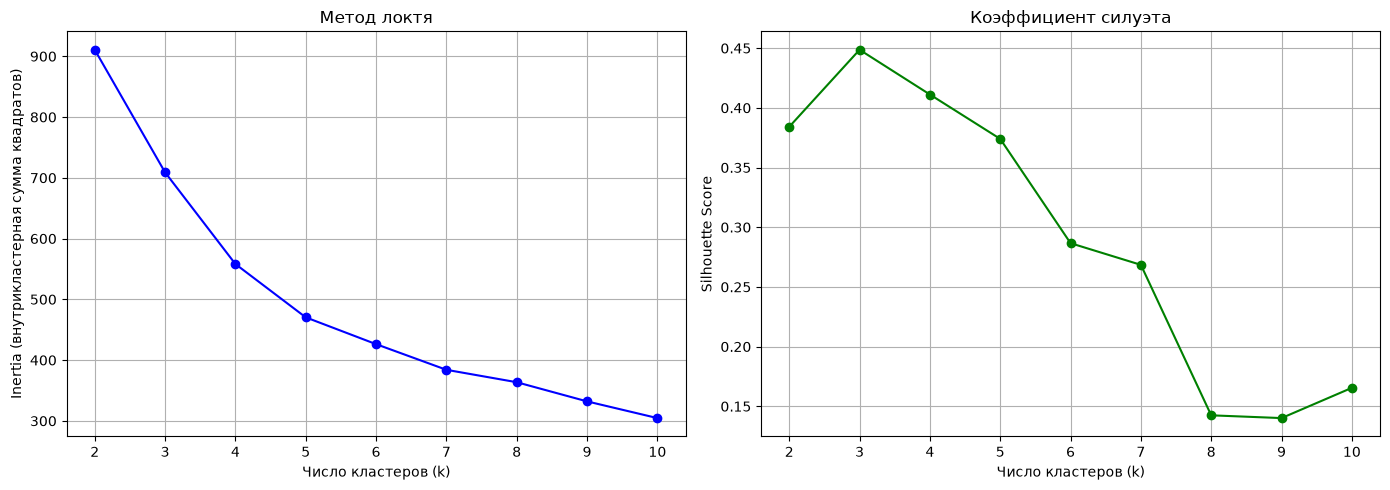

k	Inertia		Silhouette
2	910.8		0.3841
3	709.0		0.4487
4	558.1		0.4112
5	470.4		0.3740
6	426.3		0.2866
7	384.0		0.2685
8	363.6		0.1424
9	332.1		0.1401
10	304.6		0.1655


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_vals = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=123, init='k-means++', n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_vals.append(silhouette_score(X_scaled, kmeans.labels_))

plt.figure(figsize=(14, 5))

# Метод локтя
plt.subplot(1, 2, 1)
plt.plot(k_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Метод локтя')
plt.xlabel('Число кластеров (k)')
plt.ylabel('Inertia (внутрикластерная сумма квадратов)')
plt.grid(True)
plt.xticks(k_range)

# Коэффициент силуэта
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_vals, marker='o', linestyle='-', color='g')
plt.title('Коэффициент силуэта')
plt.xlabel('Число кластеров (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.xticks(k_range)

plt.tight_layout()
plt.show()

print("k\tInertia\t\tSilhouette")
for i, k in enumerate(k_range):
    print(f"{k}\t{inertia[i]:.1f}\t\t{silhouette_vals[i]:.4f}")

In [3]:
kmeans_final = KMeans(n_clusters=3, random_state=123, init='k-means++', n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_scaled)

df['KMeans_Cluster'] = kmeans_labels
print("K-means успешно обучен для k=3. Метки сохранены в df['KMeans_Cluster'].")

K-means успешно обучен для k=3. Метки сохранены в df['KMeans_Cluster'].


## 3. Провести кластеризацию данных с помощью алгоритма иерархической кластеризации.

Иерархическая кластеризация строит вложенную структуру кластеров. Агломеративный подход начинает работу с того, что каждый объект считается отдельным кластером. Затем на каждом шаге объединяются два ближайших кластера, пока не останется один.

Для визуализации процесса слияния строится дендрограмма – древовидная диаграмма, где по оси абсцисс откладываются объекты, а по оси ординат – расстояние между ними в момент объединения. Чтобы получить \(k\) кластеров, дендрограмму мысленно "разрезают" горизонтальной линией на нужном уровне.

Используем оптимальное число кластеров \(k=3\), найденное на предыдущем шаге.

Коэффициент силуэта для иерархической кластеризации: 0.3646


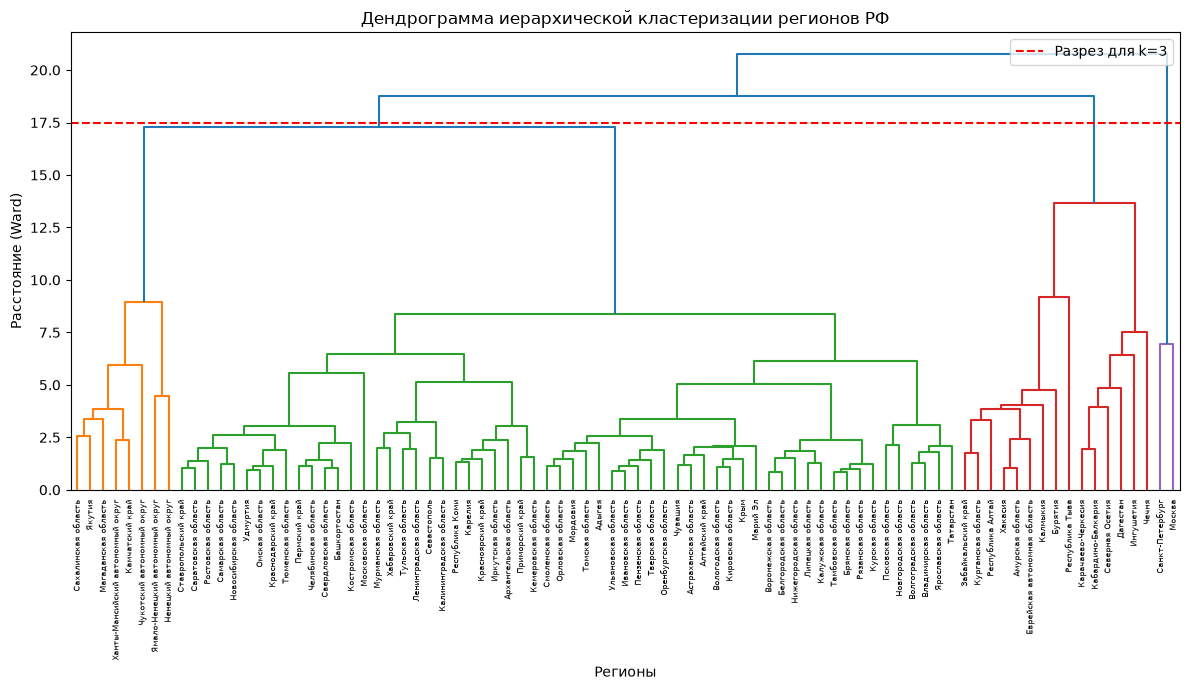

In [4]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score

hier_model = AgglomerativeClustering(n_clusters=3, linkage='ward')
hier_labels = hier_model.fit_predict(X_scaled)

df['Hier_Cluster'] = hier_labels

hier_silhouette = silhouette_score(X_scaled, hier_labels)
print(f"Коэффициент силуэта для иерархической кластеризации: {hier_silhouette:.4f}")

plt.figure(figsize=(12, 7))
linked = linkage(X_scaled, method='ward')

dendrogram(linked, orientation='top', labels=regions_rus.values, distance_sort='descending', show_leaf_counts=True, leaf_rotation=90, leaf_font_size=6)

plt.axhline(y=17.5, color='r', linestyle='--', label='Разрез для k=3')

plt.title('Дендрограмма иерархической кластеризации регионов РФ')
plt.xlabel('Регионы')
plt.ylabel('Расстояние (Ward)')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Провести кластеризацию данных с помощью алгоритма DBSCAN.

DBSCAN – алгоритм кластеризации, основанный на плотности. Он не требует заранее задавать число кластеров. Вместо этого он находит области с высокой плотностью точек, разделяя их областями низкой плотности. Точки, которые не попали ни в один кластер, помечаются как шум (метка `-1`).

**Параметры алгоритма:**
* `eps` – радиус окрестности вокруг объекта.
* `min_samples` – минимальное количество точек в окрестности радиуса `eps`, чтобы объект считался «основной» точкой (ядром).

Для подбора оптимального `eps` строится график k-расстояний. Возьмем `min_samples=5` и посмотрим на расстояния до 5-го ближайшего соседа.

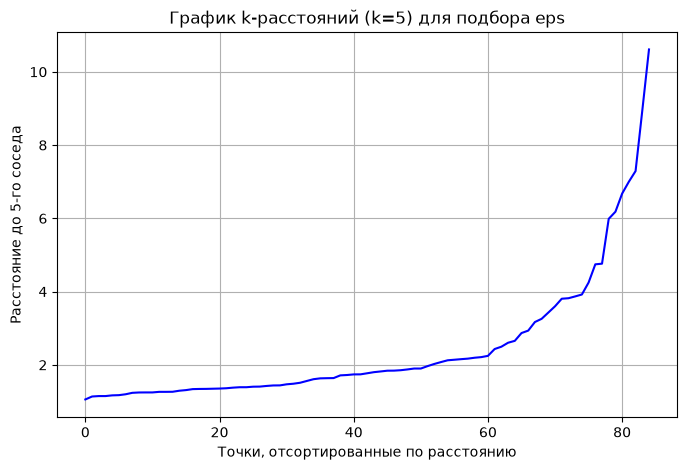

Первые 10 расстояний (мин): [1.06 1.14 1.15 1.15 1.17 1.17 1.2  1.24 1.25 1.25]
Последние 10 расстояний (макс): [ 4.25  4.74  4.76  5.99  6.18  6.68  7.    7.29  8.94 10.61]


In [5]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(distances, color='b')
plt.title('График k-расстояний (k=5) для подбора eps')
plt.xlabel('Точки, отсортированные по расстоянию')
plt.ylabel('Расстояние до 5-го соседа')
plt.grid(True)
plt.show()

print("Первые 10 расстояний (мин):", np.round(distances[:10], 2))
print("Последние 10 расстояний (макс):", np.round(distances[-10:], 2))

In [6]:
dbscan = DBSCAN(eps=1.5, min_samples=3)
dbscan_labels = dbscan.fit_predict(X_scaled)

df['DBSCAN_Cluster'] = dbscan_labels

unique_labels = set(dbscan_labels)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"Количество найденных кластеров: {n_clusters}")
print(f"Количество шумовых точек: {n_noise}")

if n_clusters > 1:
    mask = dbscan_labels != -1
    if len(set(dbscan_labels[mask])) > 1:
        db_silhouette = silhouette_score(X_scaled[mask], dbscan_labels[mask])
        print(f"Коэффициент силуэта (без учета шума): {db_silhouette:.4f}")

Количество найденных кластеров: 2
Количество шумовых точек: 43
Коэффициент силуэта (без учета шума): 0.2227


## 5. Визуализировать кластеризованные данные с помощью t-SNE или UMAP, если необходимо. Если данные трехмерные, то можно использовать трехмерный точный график.

Для визуализации 13-мерных данных используется алгоритм снижения размерности t-SNE. Он проецирует объекты в двумерное пространство так, чтобы похожие объекты оказались рядом друг с другом. Построим три графика, соответствующих результатам k-means, иерархической кластеризации и DBSCAN.

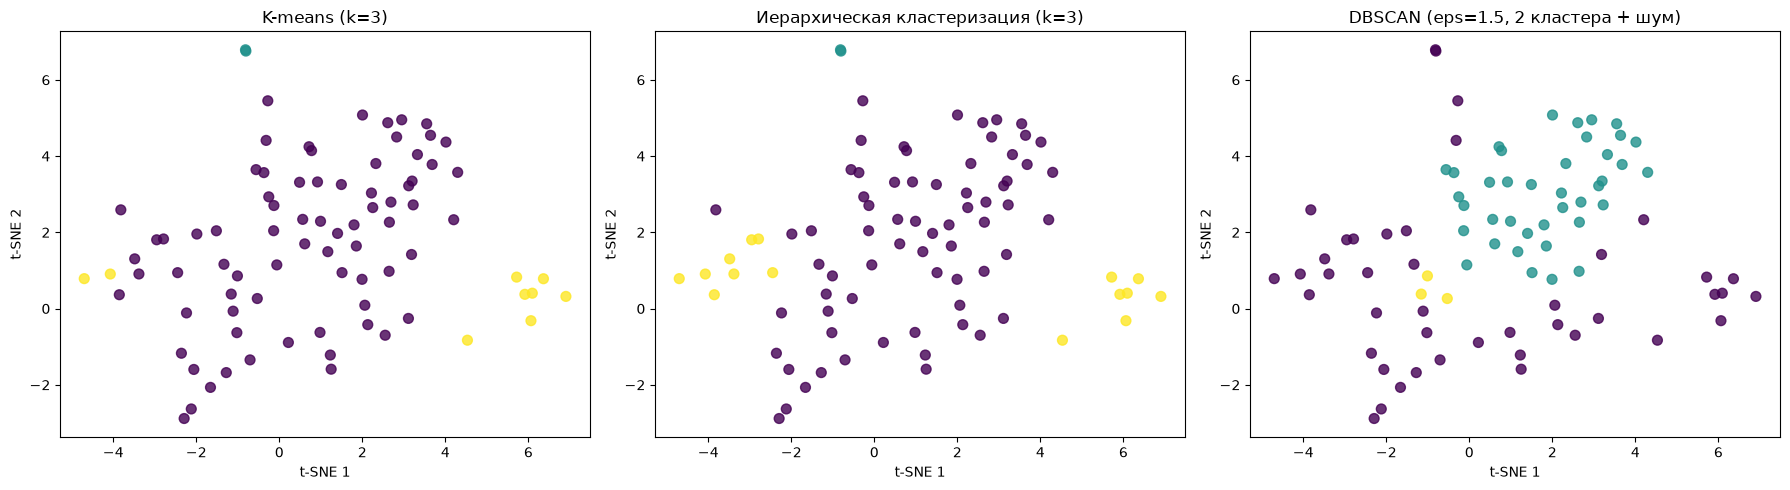

In [7]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=123, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# K-means
scatter1 = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap='viridis', s=50, alpha=0.8)
axes[0].set_title('K-means (k=3)')
axes[0].set_xlabel('t-SNE 1')
axes[0].set_ylabel('t-SNE 2')

# Иерархическая кластеризация
scatter2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=hier_labels, cmap='viridis', s=50, alpha=0.8)
axes[1].set_title('Иерархическая кластеризация (k=3)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')

# DBSCAN
scatter3 = axes[2].scatter(X_tsne[:, 0], X_tsne[:, 1], c=dbscan_labels, cmap='viridis', s=50, alpha=0.8)
axes[2].set_title('DBSCAN (eps=1.5, 2 кластера + шум)')
axes[2].set_xlabel('t-SNE 1')
axes[2].set_ylabel('t-SNE 2')

plt.tight_layout()
plt.show()

## 6. Оформить отчет о проделанной работе. Сделать выводы.

В ходе практической работы была проведена кластеризация данных о социально-экономических показателях 85 субъектов Российской Федерации. Перед применением алгоритмов данные были стандартизированы, так как признаки имели разный масштаб.

1. **K-means:** С помощью "правила локтя" и коэффициента силуэта оптимальное число кластеров было определено как \(k=3\). Коэффициент силуэта составил **0.4487**, что указывает на хорошее качество разделения. Алгоритм выделил три содержательно интерпретируемые группы регионов:
   - **Кластер 0 (74 региона):** Регионы со средними по стране показателями.
   - **Кластер 1 (2 региона):** Финансовые центры, отличающиеся максимальной плотностью населения, зарплатами, ВРП и уровнем образования.
   - **Кластер 2 (9 регионов):** Регионы с низким уровнем развития, характеризующиеся высокой безработицей, бедностью и низкими доходами.
2. **Иерархическая кластеризация:** Результаты с \(k=3\) практически полностью совпали с результатами k-means (силуэт **0.3646**), что подтверждает устойчивость найденной структуры данных. Дендрограмма наглядно показала процесс объединения регионов в 3 крупные ветви.
3. **DBSCAN:** Алгоритм, основанный на плотности, показал низкую эффективность на данном наборе данных. Из-за высокой размерности признаков (13) и отсутствия ярко выраженных "сгустков" в многомерном пространстве, алгоритм смог выделить лишь 2 кластера, отнеся 43 региона (около 50%) к шуму. Коэффициент силуэта (без учета шума) составил **0.2227**.
4. **Визуализация t-SNE:** Снижение размерности до 2D подтвердило результаты кластеризации. На графиках для k-means и иерархического метода четко видны три обособленные группы объектов, в то время как DBSCAN выделил лишь одну плотную область.

**Общий вывод:** Наиболее подходящим алгоритмом для данного набора данных оказался **k-means** (и подтверждающий его иерархический метод). Он позволил четко сегментировать регионы по уровню социально-экономического развития. DBSCAN не рекомендуется применять к исходным 13-мерным данным без предварительного снижения размерности (например, с помощью PCA).

In [8]:
print("Распределение регионов по кластерам K-means (k=3)")
for cluster in sorted(df['KMeans_Cluster'].unique()):
    print(f"\nКластер {cluster}:")
    regions_in_cluster = df[df['KMeans_Cluster'] == cluster]['Regions, rus'].tolist()
    print(", ".join(regions_in_cluster))

print("\nСредние значения признаков по кластерам (исходные данные)")
X_with_labels = X.copy()
X_with_labels['Cluster'] = kmeans_labels
display(X_with_labels.groupby('Cluster').mean().T)

Распределение регионов по кластерам K-means (k=3)

Кластер 0:
Адыгея, Алтайский край, Амурская область, Архангельская область, Астраханская область, Башкортостан, Белгородская область, Брянская область, Бурятия, Челябинская область, Чукотский автономный округ, Чувашия, Крым, Иркутская область, Ивановская область, Еврейская автономная область, Калининградская область, Калужская область, Камчатский край, Карелия, Кемеровская область, Хабаровский край, Хакасия, Ханты-Мансийский автономный округ, Кировская область, Республика Коми, Костромская область, Краснодарский край, Красноярский край, Курганская область, Курская область, Ленинградская область, Липецкая область, Магаданская область, Марий Эл, Мордовия, Московская область, Мурманская область, Ненецкий автономный округ, Нижегородская область, Новгородская область, Новосибирская область, Омская область, Оренбургская область, Орловская область, Пензенская область, Пермский край, Приморский край, Псковская область, Ростовская область, Ряза

Cluster,0,1,2
Population вensity per km2,3.229203e+01,4.398975e+03,57.017778
Total population,1.637546e+06,9.038072e+06,882890.888889
Share of people with higher education. 2010. %,1.995946e+01,3.750000e+01,18.444444
Median salary. 2019. rubles,3.454461e+04,5.867550e+04,22088.111111
Unemployment rate. 2017. %,5.605405e+00,1.550000e+00,14.344444
Share of poor people. 2017. %,1.437973e+01,8.500000e+00,24.800000
Gross regional product per capita. 2016. rubles,4.588238e+04,8.088868e+04,14323.042222
Terrorist_crimes_2017,5.648649e-02,5.500000e-02,0.977778
Murders and attempted murders. 2017,8.197297e-01,3.100000e-01,0.802222
Criminal possesion of weapons. 2017,2.107297e+00,5.250000e-01,4.701111
